# Cardio-JEPA — local run (Windows, `D:\Ishtiaque`)

This is the Kaggle notebook converted to run entirely on this machine. What changed:

| | Kaggle | Local |
|---|---|---|
| package | attached Model input | imported straight from `PROJECT_ROOT` |
| data | `/kaggle/input` auto-discovery | explicit folders under `DATASET_ROOT` (`LOCAL_DATASETS` below) |
| outputs | `/kaggle/working` | `PROJECT_ROOT\runs\<mode>\` and `PROJECT_ROOT\results\<mode>\` |
| runtime budget | forced to fit ~11 h | measured and reported, **not** forced (`AUTO_FIT_BUDGET`) |
| checkpoints | written once at the end of a model | rolling `_last.pt` every `CKPT_EVERY_STEPS` + every epoch |

**Resuming.** Every model writes `runs/<mode>/<name>_last.pt` (full training state) as it
trains. If the kernel dies, the PC reboots, or you stop the run, just re-run the notebook
from the top: finished models are reloaded instantly and the interrupted one continues from
its last checkpoint. Changing the model size, epochs, batch size or objective invalidates a
checkpoint on purpose (it is ignored with a message, never silently mis-loaded).

Run order: **setup → environment check → data → config → (stages)**. `RUN_MODE` is in the
configuration cell.

## Corrections in this version (v2)

The first full run (`runs\full`) trained nothing usable for forward prediction: the
collapse guard stopped `masked_only`, `forward_only` and `dual` at steps 1,600-1,800 of
301,700, and Stage 1/2/2c were evaluated on those stopped models. This version fixes it.

| | before | now |
|---|---|---|
| anti-collapse in `full` | EMA only (collapsed: std 0.0013, cos 1.000) | VICReg on the pooled representation |
| collapse guard | stopped runs on a false positive | `warn` (run completes; flagged only) |
| cross-window target | 400 per-patch future tokens (unpredictable phase) | standardised pooled future latent, `a_h * persistence + delta` |
| horizons trained | 10-300 s (600/1800 s buckets untrained) | 10 s-1 h, log-uniform |
| forward pairs | 200 fixed per record (~1.5 % of the Holter data) | re-drawn every access |
| test patients | the same records used in pretraining | 30 % of long records held out from pretraining |
| forecast skill | three different embedding spaces | target space, plus `mse_skill` |
| VQ temperature | 0.5 (uniform softmax -> constant targets) | 0.07 |
| Stage 4 | OOM; `STAGE4_BATCHl` typo | gradient through 2 of 12 windows, batch 16 |
| Stage 3 `ema` arm | stopped 1-epoch model reused | trained in full; `vicreg` reuses Stage 1 `dual` |
| output folders | `runs\full`, `results\full` | `runs\full_v2`, `results\full_v2` |

**What to watch:** in Stage 2c, `mse_skill > 0` for `dual` on the held-out patients is the
evidence that the model forecasts rather than copies the present.


# Cardio-JEPA — Latent Forward-Prediction JEPA for Cardiac World Modelling from ECG

Reference implementation of the research proposal *"Cardio-JEPA: Latent
Forward-Prediction Joint-Embedding Architecture for Cardiac World Modeling from ECG"*,
packaged to run start-to-finish inside one Kaggle session.

## What is new here

All three published ECG-JEPAs — Kim's ECG-JEPA (arXiv:2410.08559), Weimann & Conrad's
I-JEPA-for-ECG (arXiv:2410.13867), and the Hierarchical/ER-JEPA (arXiv:2607.01145) —
predict **masked latent patches inside a single static ~10 s recording**. None predicts
*forward in time*. Cardio-JEPA adds that:

$$\mathcal{L} \;=\; \underbrace{w_{\text{fwd}}\,\mathcal{L}_{fwd}}_{\text{dynamics (new)}}
\;+\; \underbrace{\lambda\,\mathcal{L}_{mask}}_{\text{morphology (Kim)}}
\;+\; \underbrace{\beta\,\mathcal{L}_{reg}}_{\text{anti-collapse (RQ3)}}$$

$$\mathcal{L}_{fwd}=\big\lVert g_\phi\big(f_\theta(x_{[t-L,t]}),\,h\big)-\mathrm{sg}\big(\bar f_\theta(x_{[t,t+H]})\big)\big\rVert$$

where $h$ is a learned **horizon token** so one model can be queried at 2 s … 1 h.

## Code reuse and attribution

| Source | Repository | What is reused |
|---|---|---|
| Kim, ECG-JEPA (2024) | `sehunfromdaegu/ECG_JEPA` | Cross-Pattern Attention encoder, lead-wise masked predictor, 2-D sin-cos positions, EMA schedule, linear-probe protocol |
| Assran et al., I-JEPA (CVPR 2023) | `facebookresearch/ijepa` | ViT blocks, context/target asymmetry, predictor design |
| Na et al., ST-MEM (ICLR 2024) | — | masked raw-reconstruction baseline |

Written new for this proposal: the forward predictor with horizon tokens, the two-level
hierarchical rhythm stack, the four-arm anti-collapse study, the anticipation benchmarks,
and a dependency-free WFDB reader.

## How the notebook is organised

1. **Setup** — import `cardio_jepa` from an attached Kaggle Model input, and
   optionally warm-start from a checkpoint bundled with it.
2. **Data** — auto-discover whatever ECG corpora are attached; fall back to synthetic.
3. **Stage 1 (de-risk)** — masked-only (Kim reproduction) vs forward-only vs dual, on the
   standard PTB-XL / CPSC2018 linear probe.
4. **Stage 2 (H1)** — near-term rhythm-onset anticipation, with label-efficiency curves
   and paired bootstrap tests.
5. **Stage 3 (RQ3)** — the four anti-collapse arms with effective-rank diagnostics.
6. **Stage 4 (H2)** — hierarchical vs single-scale across increasing horizons.
7. **Summary** — every table written to `/kaggle/working/results/`.

> **Run modes.** Set `RUN_MODE` in the config cell. `smoke` finishes in a few minutes
> (CPU is fine) and exercises every code path; `kaggle` is sized for one GPU session;
> `full` is the paper-scale configuration and will not finish in a single session.


## Datasets on this machine

The Kaggle mount-discovery is replaced by the explicit `LOCAL_DATASETS` map in the next cell. The remainder of this section of the original notebook (why every arm carries a variance floor, what the two long-recording corpora are for, noise-stress vs arrhythmia) still applies and is kept below.

### Why the objective arms all carry a variance floor

`L_fwd` has an exact trivial solution: if the encoder emits one constant vector, the
LayerNormed target is a fixed vector and the predictor just memorises it, driving the
loss to zero while the representation carries nothing. This is not hypothetical — under
EMA-only it happens within a few hundred steps, loss `0.39 -> 0.0001`, effective rank
`1.0`.

So all Stage 1 arms use the same anti-collapse setting (`vicreg` on the **pooled**
representation) rather than pure EMA. That keeps the objective comparison controlled —
every arm differs only in `w_fwd` and `lambda` — at the cost that `masked_only` is then
"Kim's objective plus a variance floor" rather than a bit-exact reproduction.

Pure EMA-only behaviour is not lost: it is precisely what **Stage 3** measures, which is
where the proposal's RQ3 lives.

> **`beta` is not yet validated downstream.** It was set from embedding geometry (the
> variance floor saturates at 0.1; larger values progressively replace the prediction
> objective). A linear probe could not rank it: on the synthetic AF task, β ∈ {0.1, 1,
> 5} scored 0.855 / 0.842 / 0.856 — and the *collapsed* EMA model scored **0.873**, the
> best of all. That task separates on heart rate alone, so even a degenerate
> representation wins it. Treat any AUROC ordering from synthetic data as uninformative
> about representation quality, and re-check β on PTB-XL or CPSC2018.

### Two corpora that are easy to mistake for each other

The **MIT-BIH Noise Stress Test** database (`mit-bih-noise-stress-test-database`) is
*not* the MIT-BIH Arrhythmia Database. It is 12 deliberately noise-corrupted records
plus three **pure-noise** records (`bw`, `em`, `ma` — baseline wander, electrode motion,
muscle artefact), and it carries no AF rhythm annotations. Discovery classifies it
separately, excludes the three noise-only records, and leaves it out of pretraining
unless you set `CFG.data.use_noise_corpora = True`. It is never used as an anticipation
corpus.

### On the two "required" corpora

`L_fwd` needs a *future* window. A 10 s clip does not have one, so:

* **long recordings** (LTAFDB ~24 h, MIT-BIH 30 min) drive genuine cross-window
  forecasting at horizons of seconds to tens of minutes;
* **10 s clips** drive an *intra-window causal* variant — context is the first 60 % of
  time patches, the target is the later patches, which the encoder never sees. That is
  the "short intra-recording horizons" de-risking step from Stage 1 of the proposal, and
  it makes `L_fwd` trainable on all ~800k short recordings rather than only on Holter data.

Both paths share the same predictor and the same horizon-token machinery.

**If neither LTAFDB nor MIT-BIH Arrhythmia is attached**, discovery says so explicitly
and: `L_fwd` trains only via the intra-window path, and Stages 2 and 4 fall back to
synthetic recordings — which validates the pipeline but says nothing about ECG. Stages 1
and 3 are unaffected and still produce real results from the short corpora.

## 1. Setup

In [1]:
print()

In [2]:
# --- environment, paths, package import ---------------------------------------------
import os, sys, json, time, math, warnings
import numpy as np

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = r"D:\\Ishtiaque\\Cardio-JEPA-fixed"      # contains the cardio_jepa package
DATASET_ROOT = r"D:\\Ishtiaque\\Dataset"               # all ECG corpora live here

assert os.path.isfile(os.path.join(PROJECT_ROOT, "cardio_jepa", "__init__.py")), \
    f"cardio_jepa package not found under {PROJECT_ROOT}"
WORK = PROJECT_ROOT
os.chdir(WORK)

# import the local source tree (drop any stale copy first)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
for _m in [m for m in list(sys.modules) if m == "cardio_jepa" or m.startswith("cardio_jepa.")]:
    del sys.modules[_m]

import torch
import cardio_jepa as cj
print(f"cardio_jepa {cj.__version__} loaded from {os.path.dirname(cj.__file__)}")

cardio_jepa 0.1.0 loaded from D:\\Ishtiaque\\Cardio-JEPA-fixed\cardio_jepa


## 1b. Environment check

In [3]:
# --- which folder is which corpus --------------------------------------------------
# Folder names on this disk are not Kaggle slugs, so name-matching cannot work; map each
# corpus key to its directory explicitly. Delete a line to leave a corpus out.
LOCAL_DATASETS = {
    # 12-lead, 10 s -> short-clip pretraining (+ PTB-XL / CPSC are also the linear probes)
    "ptbxl":   os.path.join(DATASET_ROOT, "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"),
    "cpsc":    os.path.join(DATASET_ROOT, "Training_WFDB"),          # CPSC2018, 6,877 records
    # WFDB_ShaoxingUniv = Chapman-Shaoxing + Ningbo (45,152 records). It is a strict
    # superset of WFDB_ChapmanShaoxing (10,247), so only this one is used: listing both
    # would load every Chapman record twice.
    "chapman": os.path.join(DATASET_ROOT, "WFDB_ShaoxingUniv"),
    # 2-channel Holter -> genuine forward prediction and the AF-onset benchmarks
    "ltaf":    os.path.join(DATASET_ROOT, "data"),                   # Long-Term AF DB, 84 x 24 h
    "afdb":    os.path.join(DATASET_ROOT, "data_2"),                 # MIT-BIH AF DB, 23 usable x 10 h
    "shdb":    os.path.join(DATASET_ROOT, "shdb-af-a-japanese-holter-ecg-database-of-atrial-fibrillation-1.0.0"),
}

In [4]:
# --- environment check: does this machine match the chosen run mode? ----------------
# Needs LOCAL_DATASETS and RUN_MODE, which are defined in the cells above/below, so the
# mode is declared here once and re-used by the configuration cell.
RUN_MODE = "full"          # "smoke" | "kaggle" | "full"

from cardio_jepa.envcheck import check_environment
ENV = check_environment(LOCAL_DATASETS, run_mode=RUN_MODE,
                        out_dir=os.path.join(WORK, "runs"))
if not ENV["ok"]:
    raise SystemExit("Fix the errors above before training.")

python   3.13.18  (Windows 11)
  torch       2.11.0+cu128   ok
  numpy       2.5.4          ok
  scipy       1.18.1         ok
  sklearn     1.9.1          ok
  pandas      3.1.1          ok
  matplotlib  3.11.2         ok
  h5py        missing        (optional)
  wfdb        missing        (optional)
              -> fine: the bundled dependency-free reader is used

torch    2.11.0+cu128   built for CUDA 12.8
gpu      NVIDIA GeForce RTX 5090  31.8 GiB  compute 12.0
  kernel test  ok (matmul fp32 + fp16 autocast on sm_120)
  bf16 supported: True

ram      31.0 GiB total, 15.8 GiB free
disk     318 GiB free on the drive holding D:\\Ishtiaque\\Cardio-JEPA-fixed\runs
cpu      16 logical cores

datasets
  ptbxl    ok       6 files, 1 subdirs   D:\\Ishtiaque\\Dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
  cpsc     ok       13754 files, 0 subdirs   D:\\Ishtiaque\\Dataset\Training_WFDB
  chapman  ok       90304 files, 0 subdirs   D:\\Ishtiaque\\Dataset\WFDB_Shao

### Package

Imported directly from `PROJECT_ROOT`; nothing to attach or upload.

## 2. Imports and device

In [5]:
# --- pull in the pieces the experiment cells use ------------------------------------
from cardio_jepa.config import configure_arm, full_config, kaggle_config, smoke_config
from cardio_jepa.data import (build_arrhythmia_onset_dataset, build_burden_dataset,
                              build_onset_dataset, discover, discover_explicit,
                              split_by_record, summarize)
from cardio_jepa.data.build import (build_pretrain_loaders, build_probe_splits,
                                    load_long_corpus, probe_batch_from_loader)
from cardio_jepa.eval import (bootstrap_auroc_delta, compare_models, forecast_skill,
                              horizon_sweep, label_efficiency_table,
                              run_anticipation_probe, run_burden_probe,
                              run_classification_probe)
from cardio_jepa.models import CardioJEPA, STMEMBaseline

import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

DEVICE = cj.pick_device()
print("cardio_jepa", cj.__version__, "| device:", DEVICE)

cardio_jepa 0.1.0 | device: cuda


In [6]:
# --- are the forward-prediction fixes installed? -----------------------------------
# This notebook needs the patched model files and the two add-on modules from
# Cardio-JEPA-local-fixes.zip (see FIXES_FULL_RUN.md). Fail early rather than train for
# a day on the old code.
_missing = [n for n in ("cross_forecast", "target_latent", "encode_context")
            if not hasattr(CardioJEPA, n)]
for _mod in ("cardio_jepa.data.forward_pairs", "cardio_jepa.eval.forecast"):
    try:
        __import__(_mod)
    except ImportError as exc:
        _missing.append(f"{_mod} ({exc})")
if _missing:
    raise SystemExit("Forward-prediction fixes not installed - missing: "
                     + ", ".join(_missing)
                     + "\nCopy the files from Cardio-JEPA-local-fixes.zip into "
                     + os.path.join(PROJECT_ROOT, "cardio_jepa") + " and restart the kernel.")
print("forward-prediction fixes: installed")


forward-prediction fixes: installed


## 3. Discover attached datasets

In [7]:
# --- what is actually on disk? ------------------------------------------------------
from cardio_jepa.data import discover_explicit
INPUT_ROOT = DATASET_ROOT
FOUND = discover_explicit(LOCAL_DATASETS, verbose=True)
print()
print(summarize(FOUND))
if not FOUND:
    print("\n>>> No corpora detected. The notebook will run on synthetic ECG so every "
          "cell still executes -- treat the numbers as a pipeline smoke test, not "
          "as evidence about ECG.")

[discovery] PTB-XL                   fmt=ptbxl      files~3170    D:\\Ishtiaque\\Dataset\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
[discovery] CPSC2018                 fmt=wfdb       files~6877    D:\\Ishtiaque\\Dataset\Training_WFDB
[discovery] Chapman-Shaoxing         fmt=wfdb       files~45152   D:\\Ishtiaque\\Dataset\WFDB_ShaoxingUniv
[discovery] Long-Term AF             fmt=wfdb       files~84      D:\\Ishtiaque\\Dataset\data
[discovery] MIT-BIH AF DB            fmt=wfdb       files~25      D:\\Ishtiaque\\Dataset\data_2
[discovery] SHDB-AF (Japan Holter)   fmt=wfdb       files~100     D:\\Ishtiaque\\Dataset\shdb-af-a-japanese-holter-ecg-database-of-atrial-fibrillation-1.0.0

key          dataset                  kind   fmt             files
--------------------------------------------------------------------
afdb         MIT-BIH AF DB            long   wfdb               25
chapman      Chapman-Shaoxing         short  wfdb            45152
cpsc         CP

## Configuration

`RUN_MODE` is the one knob that matters.

| mode | encoder | epochs | typical wall clock | use for |
|---|---|---|---|---|
| `smoke` | 96-d, 2 layers | 2 | minutes, CPU-ok | verifying every path runs |
| `kaggle` | 384-d, 8 layers | 30 | a few hours on P100/T4 | real results in one session |
| `full` | 768-d, 12 layers | 100 | days, multi-GPU | the paper-scale run |

`STAGES` selects which experiments to run — each stage trains its own models, so
dropping stages is the main way to fit the GPU budget.

**Budget.** With all stages on, the notebook pretrains **9 models**: 4 in Stage 1
(masked-only, forward-only, dual, ST-MEM), 3 more in Stage 3 (the `ema` arm reuses
Stage 1's `dual`, since they are the same run), and 2 in Stage 4. In `kaggle` mode that
is 9 × 30 epochs, so check the per-epoch time printed by Stage 1 and cut `STAGES` or
`CFG.optim.epochs` if it will not fit your session. Every stage saves checkpoints to
`runs\<mode>\`, so stages can also be run across several sessions.

In [8]:
# --- configuration ------------------------------------------------------------------
# RUN_MODE was chosen in the environment-check cell above.
STAGES   = {
    "stage1_objective_ablation": True,   # masked-only vs forward-only vs dual
    "stage2_anticipation":       True,   # H1
    "stage3_collapse":           True,   # RQ3
    "stage4_hierarchical":       True,   # H2
}

CFG = {"smoke": smoke_config, "kaggle": kaggle_config, "full": full_config}[RUN_MODE]()
CFG.data.input_root = DATASET_ROOT
CFG.data.cache_dir = os.path.join(WORK, "cache")
# one folder per mode, so a smoke run can never be mistaken for (or resumed as) a full one
# NEW output folder: the old runs\full checkpoints are from collapsed / stopped models,
# and resume=True would otherwise pick their *_last.pt files up.
RUN_TAG = "v2"
CFG.out_dir = os.path.join(WORK, "runs", f"{RUN_MODE}_{RUN_TAG}")
CFG.optim.num_workers = 0 if RUN_MODE == "smoke" else min(6, max(2, (os.cpu_count() or 4) - 2))
CFG.hierarchical.enabled = False         # switched on per-stage below

# ---- forward-prediction fixes (see FIXES_FULL_RUN.md) --------------------------------
# (1) Variance floor on the pooled representation. full_config() left this at 'ema', so
#     every Stage-1 arm of the first full run collapsed (pooled std 0.0013, cos 1.0000).
CFG.loss.anti_collapse = "vicreg"
CFG.loss.reg_target = "pooled"
CFG.loss.beta_reg = 0.1
# (2) VQ arm: temperature 0.5 on cosine logits gave a uniform softmax over 512 codes
#     (perplexity 511.9), i.e. every target = the codebook mean.
CFG.loss.vq_temperature = 0.07
# (3) Never abandon a run on the loss-ratio test. It compared every loss against the
#     step-5 value of an untrained network and stopped masked_only / forward_only / dual
#     at steps 1600-1800 of 301,700. With 'warn' the run continues and is only flagged.
CFG.optim.on_collapse = "warn"
# (4) Cross-window forecasting: predict the *pooled* future window latent, standardised,
#     as  a_h * persistence + delta  (starts exactly at persistence, learns the change).
CFG.forward.cross_target = "pooled"
CFG.forward.standardize_target = True
CFG.forward.residual_persistence = True
# (5) Horizons must cover every horizon that is evaluated (Stage 2 @ 900 s, Stage 2c up
#     to 3600 s, Stage 4 up to 3600 s). Drawn log-uniformly between 10 s and 1 h.
CFG.forward.horizons_s = (10.0, 30.0, 60.0, 300.0, 600.0, 1800.0, 3600.0)
CFG.forward.horizon_loguniform = True
# (6) Context: 6 x 10 s = 1 min, but only the 2 most recent windows carry gradient, so
#     encoder memory per sample is the same as the old 2-window setup.
CFG.forward.context_windows = 6 if RUN_MODE != "smoke" else 2
CFG.forward.grad_context_windows = 2

# ---- batch size vs GPU memory (measured on an RTX 5090, 32 GiB, fused attention) ------
# full model (768d x 12L, 197M params): batch 32 -> 20 GiB, 40 -> 25 GiB, 64 -> does not
# fit (spills into system RAM and runs ~40x slower). Stage 4 feeds 12 windows per sample
# and only fits at batch 8 (24 GiB). Smaller GPUs: lower both.
if RUN_MODE == "full":
    CFG.optim.batch_size = 32
# Stage 4 now back-props through only 2 of its 12 context windows (grad_context_windows),
# so it fits a much larger batch than the old 8. Drop to 8 if the 5090 still runs out.
STAGE4_BATCH = 16 if RUN_MODE == "full" else CFG.optim.batch_size

# Which Stage-1 arms to train. Suggested first pass: ("dual",) with EPOCHS = 30 -- check
# that Stage 2c shows positive held-out mse_skill before paying for the other arms.
# Each full-mode arm is ~22 h at 100 epochs on the 5090.
STAGE1_ARMS = ("masked_only", "forward_only", "dual", "st_mem")
EPOCHS = None              # None = the mode's default (100 in full); e.g. 30 for a first pass
if EPOCHS is not None:
    CFG.optim.epochs = EPOCHS
# Fraction of long recordings held out from pretraining and used as the Stage 2/2c/4
# test patients (record-level, stratified by AF burden).
HOLDOUT_FRAC = 0.3

# The long (Holter) corpora present on this disk. `mitbih` is absent here but harmless.
CFG.data.long_datasets = ("ltaf", "afdb", "shdb", "mitbih")

# Optional compute cap: None = a real pass over the data per epoch (paper-style).
# e.g. 1000 turns an "epoch" into a fixed 1000-step budget. kaggle_config already sets one.
MAX_STEPS_PER_EPOCH = None
if MAX_STEPS_PER_EPOCH is not None:
    CFG.optim.max_steps_per_epoch = MAX_STEPS_PER_EPOCH

# ---- run checkpoints ---------------------------------------------------------------
CKPT_EVERY_STEPS   = 500     # rolling <name>_last.pt (model+EMA+optimiser+scaler+step)
KEEP_EVERY_EPOCHS  = 10      # also keep a model-only <name>_epNNN.pth every N epochs (0=off)
CKPT_KW = dict(resume=True, ckpt_every_steps=CKPT_EVERY_STEPS,
               keep_every_epochs=KEEP_EVERY_EPOCHS)

RESULTS_DIR = os.path.join(WORK, "results", f"{RUN_MODE}_{RUN_TAG}")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CFG.out_dir, exist_ok=True)
RESULTS = {}


def save_results():
    """Write every table produced so far -- called after each stage, so a crash in
    Stage 4 does not lose Stages 1-3."""
    scal = {}
    for name, obj in RESULTS.items():
        if isinstance(obj, pd.DataFrame):
            obj.to_csv(os.path.join(RESULTS_DIR, f"{name}.csv"), index=True)
        else:
            scal[name] = obj
    with open(os.path.join(RESULTS_DIR, "scalars.json"), "w") as fh:
        json.dump(scal, fh, indent=2, default=str)


def show_checkpoints():
    """What is on disk for this run mode (and whether a model can resume)."""
    rows = []
    for fn in sorted(os.listdir(CFG.out_dir)):
        if fn.endswith((".pth", ".pt")):
            p = os.path.join(CFG.out_dir, fn)
            rows.append({"file": fn, "MB": round(os.path.getsize(p) / 1e6, 1),
                         "modified": time.strftime("%Y-%m-%d %H:%M",
                                                   time.localtime(os.path.getmtime(p))),
                         "state": ("resumable" if fn.endswith("_last.pt")
                                   else "snapshot" if "_ep" in fn else "final")})
    return pd.DataFrame(rows) if rows else "(no checkpoints yet)"


cj.set_seed(CFG.optim.seed)
print(f"mode={RUN_MODE}  encoder={CFG.model.encoder_embed_dim}d x {CFG.model.encoder_depth}L  "
      f"epochs={CFG.optim.epochs}  batch={CFG.optim.batch_size}  "
      f"workers={CFG.optim.num_workers}")
print(f"window: {CFG.signal.window_s}s @ {CFG.signal.fs}Hz -> "
      f"{CFG.signal.n_leads} leads x {CFG.signal.n_time_patches} patches "
      f"= {CFG.signal.n_tokens} tokens")
print("horizon buckets (s):", list(cj.HORIZON_BUCKETS_S))
print(f"forward: context={CFG.forward.context_windows} windows "
      f"(grad on last {CFG.forward.grad_context_windows}), target={CFG.forward.cross_target}, "
      f"horizons {CFG.forward.horizons_s[0]:.0f}-{CFG.forward.horizons_s[-1]:.0f}s, "
      f"anti_collapse={CFG.loss.anti_collapse} (beta={CFG.loss.beta_reg})")
print("checkpoints ->", CFG.out_dir)
display(show_checkpoints())

mode=full  encoder=768d x 12L  epochs=100  batch=32  workers=6
window: 10.0s @ 250Hz -> 8 leads x 50 patches = 400 tokens
horizon buckets (s): [2.0, 5.0, 10.0, 30.0, 60.0, 300.0, 600.0, 1800.0, 3600.0]
forward: context=6 windows (grad on last 2), target=pooled, horizons 10-3600s, anti_collapse=vicreg (beta=0.1)
checkpoints -> D:\\Ishtiaque\\Cardio-JEPA-fixed\runs\full_v2


,file,MB,modified,state
0,dual.pth,790.1,2026-11-21 22:30,final
1,dual_ep010.pth,790.1,2026-11-21 00:29,snapshot
2,dual_ep020.pth,790.1,2026-11-21 02:55,snapshot
3,dual_ep030.pth,790.1,2026-11-21 05:20,snapshot
4,dual_ep040.pth,790.1,2026-11-21 07:46,snapshot
5,dual_ep050.pth,790.1,2026-11-21 10:11,snapshot
6,dual_ep060.pth,790.1,2026-11-21 12:36,snapshot
7,dual_ep070.pth,790.1,2026-11-21 15:05,snapshot
8,dual_ep080.pth,790.1,2026-11-21 17:32,snapshot
9,dual_ep090.pth,790.1,2026-11-21 20:03,snapshot


### Warm-starting from another run (optional)

Resuming an interrupted run needs nothing here — it is automatic (see the intro). This
cell is only for seeding a *new* run from an older model's weights. It is **off** by
default: a from-scratch full run should not inherit weights from a smoke or Kaggle run.
Set `WARM_START` to a `.pth` path to enable it.

In [9]:
# --- optional warm start ------------------------------------------------------------
WARM_START = "off"      # "off" | an explicit path to a .pth

WARM_START_PATH = None if WARM_START == "off" else WARM_START
if WARM_START_PATH and not os.path.isfile(WARM_START_PATH):
    print(f">>> {WARM_START_PATH} does not exist - starting from scratch instead")
    WARM_START_PATH = None
print("warm start:", WARM_START_PATH or "none (fresh init; interrupted runs still resume)")


def maybe_warm_start(model, name=""):
    """Apply the warm start, if one is configured. Returns the load report or None."""
    if not WARM_START_PATH:
        return None
    rep = cj.load_weights(model, WARM_START_PATH, strict=False, verbose=False)
    print(f"    warm start [{name}]: {rep.summary().splitlines()[0]}")
    if rep.shape_mismatch:
        print(f"      {len(rep.shape_mismatch)} tensors skipped on shape mismatch")
    return rep

warm start: none (fresh init; interrupted runs still resume)


### Build loaders

In [10]:
# --- build loaders and probe splits -------------------------------------------------
from cardio_jepa.data.forward_pairs import (build_forward_loader, combine_loaders,
                                            holdout_long_records, restrict_to_records)

t0 = time.time()
LONG_RECORDS = load_long_corpus(FOUND, CFG, verbose=True)

# Hold long recordings out of pretraining *before* building the loader. The first run
# pretrained on every Holter record and then tested Stage 2/2c/4 on the same patients.
TRAIN_IDS, HELD_IDS = holdout_long_records(LONG_RECORDS, test_frac=HOLDOUT_FRAC,
                                           seed=CFG.optim.seed)
TRAIN_LONG = [LONG_RECORDS[i] for i in TRAIN_IDS]

# Short-clip loader from the package as before (long_records=[] -> no long loader here).
_SRC, DATA_INFO = build_pretrain_loaders(FOUND, CFG, long_records=[], verbose=True)
SHORT_LOADER = next((l for l in _SRC.loaders
                     if "ForwardPair" not in type(l.dataset).__name__), None)

# Forward pairs: re-drawn on every access (fresh record, start and horizon), so the whole
# of every training Holter record is used -- the old fixed 200 pairs/record covered ~1.5%.
LONG_LOADER = build_forward_loader(TRAIN_LONG, CFG,
                                   samples_per_record=200 if RUN_MODE != "smoke" else 32)
LOADER = combine_loaders(SHORT_LOADER, LONG_LOADER, long_weight=2.0)
DATA_INFO["steps_per_epoch"] = len(LOADER)
DATA_INFO["n_forward_pairs"] = len(LONG_LOADER.dataset) if LONG_LOADER is not None else 0

PROBE_BATCH = probe_batch_from_loader(LOADER, n=128 if RUN_MODE != "smoke" else 32)
PROBE_SPLITS = build_probe_splits(FOUND, CFG, verbose=True)

print(f"\nready in {time.time() - t0:.1f}s")
print(f"  short clips     : {DATA_INFO.get('n_short', 0)}")
print(f"  forward pairs   : {DATA_INFO['n_forward_pairs']} per epoch (re-drawn every access)")
print(f"  long recordings : {len(LONG_RECORDS)} "
      f"({sum(r.duration_s for r in LONG_RECORDS) / 3600:.1f} h total)")
print(f"    pretraining   : {len(TRAIN_IDS)} records "
      f"({sum(LONG_RECORDS[i].duration_s for i in TRAIN_IDS) / 3600:.1f} h)")
print(f"    held out      : {len(HELD_IDS)} records "
      f"({sum(LONG_RECORDS[i].duration_s for i in HELD_IDS) / 3600:.1f} h) "
      f"-> Stage 2 / 2c / 4 test patients")
print(f"  probe tasks     : {list(PROBE_SPLITS)}")
print(f"  steps/epoch     : {DATA_INFO['steps_per_epoch']}")

n_rhythm = sum(1 for r in LONG_RECORDS if r.episodes)
if n_rhythm == 0:
    print("\n>>> No rhythm annotations found: the anticipation benchmarks need `.atr` "
          "rhythm labels (LTAFDB / MIT-BIH). Stage 2 will be skipped.")
else:
    burdens = [r.burden() for r in LONG_RECORDS if r.episodes]
    print(f"  AF burden       : mean {np.mean(burdens):.3f} over {n_rhythm} records "
          f"(train {np.mean([LONG_RECORDS[i].burden() for i in TRAIN_IDS]):.3f} / "
          f"held-out {np.mean([LONG_RECORDS[i].burden() for i in HELD_IDS]):.3f})")


[data] Long-Term AF             84 long records (84 with rhythm annotations, total 1960.6 h)
[data] MIT-BIH AF DB            23 long records (23 with rhythm annotations, total 234.3 h)
[data] SHDB-AF (Japan Holter)  100 long records (100 with rhythm annotations, total 2378.7 h)
[data] Chapman-Shaoxing       indexed   45152 recordings
[data] CPSC2018               indexed    6877 recordings
[data] PTB-XL                 indexed    3169 recordings
[data] 1 loader(s), 1724 steps/epoch, batch=32
[probe] PTB-XL: 2371 train / 406 test, 5 superdiagnostic classes
[probe] CPSC2018: 5502 train / 1375 test, 9 classes

ready in 66.9s
  short clips     : 55198
  forward pairs   : 29200 per epoch (re-drawn every access)
  long recordings : 207 (4573.6 h total)
    pretraining   : 146 records (3267.2 h)
    held out      : 61 records (1306.4 h) -> Stage 2 / 2c / 4 test patients
  probe tasks     : ['ptbxl', 'cpsc']
  steps/epoch     : 2636
  AF burden       : mean 0.358 over 207 records (train 0.356 

### Runtime projection — read this before the long run

The cell below times real steps on this GPU and projects the total. Locally there is no
12-hour session limit, so by default it **only reports**. With `RUN_MODE="full"` and all
four stages the notebook trains **9 models × 100 epochs**; the projection tells you
whether that means hours or days. If you want it to fit a budget instead, set
`AUTO_FIT_BUDGET = True` (caps `max_steps_per_epoch`) or lower `CFG.optim.epochs`,
`STAGES`, or `MAX_STEPS_PER_EPOCH` above.

In [11]:
# --- runtime projection --------------------------------------------
from cardio_jepa.engine import budget_steps_per_epoch, estimate_runtime, report_runtime

BUDGET_HOURS   = 24.0      # the budget AUTO_FIT_BUDGET fits to, and the warning threshold
AUTO_FIT_BUDGET = False    # True = shrink max_steps_per_epoch to fit BUDGET_HOURS

N_MODELS = (4 if STAGES["stage1_objective_ablation"] else 0) \
         + (3 if STAGES["stage3_collapse"] else 0) \
         + (2 if STAGES["stage4_hierarchical"] else 0)
N_MODELS = max(N_MODELS, 1)

_probe_model = CardioJEPA(CFG.signal, CFG.model, CFG.loss, CFG.hierarchical, CFG.forward)
EST = estimate_runtime(_probe_model, LOADER, CFG, DEVICE, n_steps=10, n_models=N_MODELS)
del _probe_model
if DEVICE.type == "cuda":
    print(f"peak GPU memory during the timing steps: "
          f"{torch.cuda.max_memory_allocated() / 2**30:.1f} GiB of "
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GiB")
    torch.cuda.empty_cache()

print(f"{N_MODELS} model(s) to train, {CFG.optim.epochs} epochs, "
      f"max_steps_per_epoch={CFG.optim.max_steps_per_epoch}")
print(report_runtime(EST, budget_hours=BUDGET_HOURS))

if EST["hours_total"] > BUDGET_HOURS and AUTO_FIT_BUDGET:
    fits = budget_steps_per_epoch(EST["s_per_step"], CFG.optim.epochs, N_MODELS,
                                  BUDGET_HOURS)
    print(f"\n  AUTO_FIT_BUDGET: CFG.optim.max_steps_per_epoch = {fits}")
    CFG.optim.max_steps_per_epoch = fits
    print(report_runtime(estimate_runtime(
        CardioJEPA(CFG.signal, CFG.model, CFG.loss, CFG.hierarchical, CFG.forward),
        LOADER, CFG, DEVICE, n_steps=4, n_models=N_MODELS), budget_hours=BUDGET_HOURS))
elif EST["hours_total"] > BUDGET_HOURS:
    print("\n  (AUTO_FIT_BUDGET is off - training will take the full projected time. "
          "Progress is checkpointed, so you can stop and resume at any point.)")

RESULTS["runtime_estimate"] = dict(EST)

peak GPU memory during the timing steps: 15.0 GiB of 32 GiB
9 model(s) to train, 100 epochs, max_steps_per_epoch=None
  0.355 s/step x 2636 steps/epoch x epochs = 263600 steps/model
  ~25.98 h per model, ~233.79 h for 9 model(s)
  >>> 9.7x over a ~24 h session. This will not finish; reduce the budget before starting, not eight hours in.

  (AUTO_FIT_BUDGET is off - training will take the full projected time. Progress is checkpointed, so you can stop and resume at any point.)


## Stage 1 — De-risk: does adding $\mathcal{L}_{fwd}$ cost anything on standard classification?

Three architecturally **identical** models, differing only in the objective:

| arm | $w_{fwd}$ | $\lambda$ | what it is |
|---|---|---|---|
| `masked_only` | 0 | 1 | Kim's ECG-JEPA, reproduced |
| `forward_only` | 1 | 0 | the new objective alone |
| `dual` | 1 | 1 | **Cardio-JEPA** |
| `st_mem` | — | — | raw-signal reconstruction baseline |

Go/no-go from the proposal: *the dual objective must match the masked-only baseline on
standard classification (within CI) before proceeding.* Linear probing on frozen
encoders, macro-AUROC, with paired bootstrap CIs.


In [12]:
# --- Stage 1: objective ablation ----------------------------------------------------
import copy

def build_objective_arm(name):
    cfg = copy.deepcopy(CFG)
    cfg.name = f"{CFG.name}_{name}"
    if name == "masked_only":
        cfg.loss.weight_forward, cfg.loss.lambda_mask = 0.0, 1.0
    elif name == "forward_only":
        cfg.loss.weight_forward, cfg.loss.lambda_mask = 1.0, 0.0
    elif name == "dual":
        cfg.loss.weight_forward, cfg.loss.lambda_mask = 1.0, 1.0
    return cfg


def train_one(name, cfg, model=None):
    print(f"\n=== training [{name}] ===")
    if model is None:
        model = CardioJEPA(cfg.signal, cfg.model, cfg.loss, cfg.hierarchical, cfg.forward)
    n_par = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f"    {n_par:.1f}M trainable parameters")
    maybe_warm_start(model, name)
    res = cj.pretrain(model, LOADER, cfg, device=DEVICE, arm_name=name,
                      probe_batch=PROBE_BATCH,
                      save_path=os.path.join(cfg.out_dir, f"{name}.pth"),
                      log_every=0 if RUN_MODE == "smoke" else 100, **CKPT_KW)
    if res.collapsed:
        print(f"    [{name}] COLLAPSED at step {res.collapse_step}: {res.collapse_reason}")
        print(f"    Its probe numbers below are meaningless - a collapsed encoder "
              f"carries no signal for any linear head.")
    _report_forward(name, res)
    return model, res


def _report_forward(name, res):
    """Cross-window forecast diagnostics from the training history.

    The epoch line's `fwd=` mixes intra-window and cross-window batches; these keys come
    from cross-window batches only. (They are averaged over *all* batches by the engine,
    so absolute values are scaled down by the cross-window share of steps; the trend and
    the sign of `fwd_skill` are what matter.)
    """
    h = [e for e in res.history if "fwd_skill" in e]
    if not h:
        return
    first, last = h[0], h[-1]
    print(f"    [{name}] cross-window: loss {first.get('loss_fwd_cross', float('nan')):.4f}"
          f" -> {last.get('loss_fwd_cross', float('nan')):.4f}, "
          f"train skill {first['fwd_skill']:+.4f} -> {last['fwd_skill']:+.4f}")


STAGE1 = {}
if STAGES["stage1_objective_ablation"]:
    for arm in [a for a in STAGE1_ARMS if a != "st_mem"]:
        cfg = build_objective_arm(arm)
        model, res = train_one(arm, cfg)
        STAGE1[arm] = {"model": model, "res": res, "cfg": cfg}

    # ST-MEM style raw-reconstruction baseline (same encoder, different target space)
    if "st_mem" in STAGE1_ARMS:
        stmem_cfg = copy.deepcopy(CFG)
        stmem = STMEMBaseline(stmem_cfg.signal, stmem_cfg.model)
        _, stmem_res = train_one("st_mem", stmem_cfg, model=stmem)
        STAGE1["st_mem"] = {"model": stmem, "res": stmem_res, "cfg": stmem_cfg}
    print("\nStage 1 training complete.")
else:
    print("Stage 1 skipped.")


=== training [masked_only] ===
    111.7M trainable parameters
  [resume] masked_only.pth is already complete (100 epochs) - loaded, not retrained

=== training [forward_only] ===
    111.7M trainable parameters
  [resume] forward_only.pth is already complete (100 epochs) - loaded, not retrained
    [forward_only] cross-window: loss 0.8856 -> 0.4332, train skill -0.0001 -> +0.0823

=== training [dual] ===
    111.7M trainable parameters
  [resume] dual.pth is already complete (100 epochs) - loaded, not retrained
    [dual] cross-window: loss 0.8828 -> 0.4185, train skill -0.0001 -> +0.1575

=== training [st_mem] ===
    96.1M trainable parameters
  [resume] st_mem.pth is already complete (100 epochs) - loaded, not retrained

Stage 1 training complete.


In [13]:
# --- Stage 1: linear probing on the standard benchmarks -----------------------------
stage1_rows, stage1_scores, stage1_frac = [], {}, {}

if STAGE1 and PROBE_SPLITS:
    for task_name, splits in PROBE_SPLITS.items():
        print(f"\n### linear probe: {task_name} "
              f"({splits['n_classes']} classes, {len(splits['train'])} train)")
        task_scores = {}
        for arm, entry in STAGE1.items():
            print(f"  [{arm}]")
            out = run_classification_probe(entry["model"], splits, DEVICE, CFG.evaluation,
                                           batch_size=64, num_workers=0, verbose=False)
            stage1_rows.append({"task": task_name, "arm": arm,
                                "macro_auroc": out["macro_auroc"],
                                "macro_f1": out["by_fraction"][1.0].get("macro_f1"),
                                "feature_dim": out["feature_dim"],
                                "collapsed": bool(entry["res"].collapsed)})
            task_scores[arm] = out["y_score"]
            stage1_frac[f"{task_name}/{arm}"] = {
                f: r["macro_auroc"] for f, r in out["by_fraction"].items()}
            print(f"    macro AUROC = {out['macro_auroc']:.4f}")
        stage1_scores[task_name] = (splits, task_scores,
                                    out["y_true"])   # y_true is shared across arms

    stage1_df = pd.DataFrame(stage1_rows)
    RESULTS["stage1_linear_probe"] = stage1_df
    display(stage1_df.pivot(index="arm", columns="task", values="macro_auroc")
            .round(4).sort_values(by=list(stage1_df.task.unique())[0], ascending=False))

    # go/no-go: dual vs masked-only, paired bootstrap
    for task_name, (_s, scores, y_true) in stage1_scores.items():
        if "dual" in scores and "masked_only" in scores:
            d = bootstrap_auroc_delta(y_true, scores["dual"], scores["masked_only"],
                                      n=CFG.evaluation.bootstrap_n)
            verdict = ("GO - dual matches or beats masked-only"
                       if d["delta"] >= 0 or not d["significant"]
                       else "NO-GO - dual is significantly worse")
            print(f"\n[{task_name}] dual - masked_only = {d['delta']:+.4f} "
                  f"[{d['lo']:+.4f}, {d['hi']:+.4f}]  p={d['p_value']:.3f}")
            print(f"  -> {verdict}")
            RESULTS[f"stage1_gonogo_{task_name}"] = d
else:
    print("Stage 1 evaluation skipped (no trained models or no labelled probe task).")

save_results()


### linear probe: ptbxl (5 classes, 2371 train)
  [masked_only]
    macro AUROC = 0.7861
  [forward_only]
    macro AUROC = 0.6728
  [dual]
    macro AUROC = 0.8113
  [st_mem]
    macro AUROC = 0.8762

### linear probe: cpsc (9 classes, 5502 train)
  [masked_only]
    macro AUROC = 0.8447
  [forward_only]
    macro AUROC = 0.7474
  [dual]
    macro AUROC = 0.8665
  [st_mem]
    macro AUROC = 0.9479


task,cpsc,ptbxl
arm,,
st_mem,0.9479,0.8762
dual,0.8665,0.8113
masked_only,0.8447,0.7861
forward_only,0.7474,0.6728



[ptbxl] dual - masked_only = +0.0252 [-0.0030, +0.0524]  p=0.074
  -> GO - dual matches or beats masked-only

[cpsc] dual - masked_only = +0.0218 [+0.0094, +0.0340]  p=0.000
  -> GO - dual matches or beats masked-only


## Stage 2 — H1: near-term rhythm-onset anticipation

Given a context window **containing no AF at all**, predict whether an AF episode
*starts* within the next $H$ seconds.

Leakage control (proposal Section 9) is enforced in `build_onset_dataset`:

* the context window must not overlap the target rhythm anywhere;
* a guard band after the context is discarded, so a window whose event begins at its
  very edge is dropped rather than counted as a negative;
* a negative requires the **full horizon to be observed** — windows near the end of a
  record cannot be negatives, because absence there is unobserved, not known;
* train/test are split **by record (patient)**, never by window.

Two feature modes are compared, which is where the world-model claim is actually tested:

* `context` — the pooled frozen encoder embedding (available to every method);
* `world` — `[context embedding ‖ predicted future latent at H]`, i.e. the probe also
  sees *where the model thinks the heart is heading*. Only models with a forward
  predictor have this.

> **Scope note.** This is benchmark 3 from Section 6.2 (near-term, within-record
> anticipation). Benchmark 2 — Attia-style *latent AF*, "will this patient be diagnosed
> within 30 days" — needs patient-level longitudinal diagnosis labels that none of the
> public Kaggle mirrors carry. The dataset builder is horizon-agnostic and would accept
> such labels directly, but no such result is produced here, and none should be claimed.


In [14]:
# --- Stage 2: anticipation (H1) -----------------------------------------------------
ANTICIPATION_H = 300.0 if RUN_MODE == "smoke" else 900.0   # seconds

stage2_df = None
if STAGES["stage2_anticipation"] and STAGE1 and any(r.episodes for r in LONG_RECORDS):
    samples, stats = build_onset_dataset(
        LONG_RECORDS, CFG.signal, horizon_s=ANTICIPATION_H,
        context_windows=CFG.forward.context_windows,
        stride_s=CFG.evaluation.anticipation_stride_s,
        guard_s=CFG.evaluation.anticipation_guard_s,
        max_per_record=400 if RUN_MODE != "smoke" else 60)
    print(f"AF-onset dataset @ H={ANTICIPATION_H:.0f}s: "
          f"{stats['n_positive']:.0f} positive / {stats['n_negative']:.0f} negative "
          f"(prevalence {stats['prevalence']:.3f})")

    # test patients = the records held out from pretraining
    tr = restrict_to_records(samples, TRAIN_IDS)
    te = restrict_to_records(samples, HELD_IDS)
    print(f"record-level split (pretraining hold-out): {len(tr)} train / {len(te)} test "
          f"windows, test positives {sum(s.label > 0.5 for s in te)}")

    rows, scores, y_ref = [], {}, None
    n_te_pos = sum(s.label > 0.5 for s in te)
    if (stats["n_positive"] >= 10 and stats["n_negative"] >= 10 and tr and te
            and 5 <= n_te_pos <= len(te) - 5):
        for arm, entry in STAGE1.items():
            has_predictor = hasattr(entry["model"], "forward_predictor")
            for mode in (("context", "world") if has_predictor else ("context",)):
                r = run_anticipation_probe(
                    entry["model"], LONG_RECORDS, tr, te, CFG.signal, DEVICE,
                    CFG.evaluation, context_windows=CFG.forward.context_windows,
                    feature_mode=mode, horizons_s=[ANTICIPATION_H],
                    batch_size=64, verbose=False)
                if np.isnan(r.get("auroc", float("nan"))):
                    print(f"  {arm}/{mode}: {r.get('note', 'no result')}")
                    continue
                name = f"{arm}/{mode}"
                rows.append({"arm": arm, "features": mode, "auroc": r["auroc"],
                             "ci_lo": r["ci_lo"], "ci_hi": r["ci_hi"],
                             "n_test": r["n_test"], "prevalence": r["prevalence"]})
                scores[name] = r["y_score"]
                y_ref = r["y_true"]
                stage1_frac[f"anticipation/{name}"] = r["by_fraction"]
                print(f"  {name:26s} AUROC={r['auroc']:.4f} "
                      f"[{r['ci_lo']:.4f}, {r['ci_hi']:.4f}]")

        if rows:
            stage2_df = pd.DataFrame(rows).sort_values("auroc", ascending=False)
            RESULTS["stage2_anticipation"] = stage2_df
            display(stage2_df.round(4))

            ref = "masked_only/context"
            if ref in scores and y_ref is not None:
                print(f"\npaired bootstrap vs {ref}:")
                display(compare_models(y_ref, scores, reference=ref,
                                       n=CFG.evaluation.bootstrap_n).round(4))
    else:
        print("Not enough positive/negative windows for a meaningful probe.")
else:
    print("Stage 2 skipped (needs trained models and rhythm-annotated long recordings).")

save_results()

AF-onset dataset @ H=900s: 5839 positive / 60822 negative (prevalence 0.088)
record-level split (pretraining hold-out): 47346 train / 19315 test windows, test positives 2021
  masked_only/context        AUROC=0.6339 [0.6208, 0.6459]
  masked_only/world          AUROC=0.6236 [0.6086, 0.6378]
  forward_only/context       AUROC=0.5788 [0.5653, 0.5916]
  forward_only/world         AUROC=0.6327 [0.6194, 0.6454]
  dual/context               AUROC=0.6266 [0.6140, 0.6388]
  dual/world                 AUROC=0.6728 [0.6583, 0.6875]
  st_mem/context             AUROC=0.7667 [0.7559, 0.7768]


,arm,features,auroc,ci_lo,ci_hi,n_test,prevalence
6,st_mem,context,0.7667,0.7559,0.7768,19315,0.1046
5,dual,world,0.6728,0.6583,0.6875,19315,0.1046
0,masked_only,context,0.6339,0.6208,0.6459,19315,0.1046
3,forward_only,world,0.6327,0.6194,0.6454,19315,0.1046
4,dual,context,0.6266,0.6140,0.6388,19315,0.1046
1,masked_only,world,0.6236,0.6086,0.6378,19315,0.1046
2,forward_only,context,0.5788,0.5653,0.5916,19315,0.1046



paired bootstrap vs masked_only/context:


,model,auroc,ci_lo,ci_hi,delta_vs_ref,delta_lo,delta_hi,p_value,significant
0,st_mem/context,0.7667,0.7559,0.7768,0.1329,0.1203,0.1452,0.000,True
1,dual/world,0.6728,0.6583,0.6875,0.0389,0.0224,0.0561,0.000,True
2,masked_only/context,0.6339,0.6208,0.6459,NaN,NaN,NaN,NaN,NaN
3,forward_only/world,0.6327,0.6194,0.6454,-0.0011,-0.0165,0.0144,0.874,False
4,dual/context,0.6266,0.6140,0.6388,-0.0072,-0.0199,0.0059,0.280,False
5,masked_only/world,0.6236,0.6086,0.6378,-0.0103,-0.0216,0.0011,0.088,False
6,forward_only/context,0.5788,0.5653,0.5916,-0.0550,-0.0711,-0.0397,0.000,True


In [15]:
# --- Stage 2b: label-efficiency curves (the second half of H1) -----------------------
if stage1_frac:
    eff = {k: v for k, v in stage1_frac.items() if k.startswith("anticipation/")}
    if not eff:
        eff = stage1_frac
    eff_df = label_efficiency_table(eff).round(4)
    RESULTS["label_efficiency"] = eff_df
    print("macro AUROC by fraction of labels used "
          "(H1 predicts the Cardio-JEPA margin *grows* as labels shrink):")
    display(eff_df)
else:
    print("No label-efficiency results to report.")

save_results()

macro AUROC by fraction of labels used (H1 predicts the Cardio-JEPA margin *grows* as labels shrink):


,1%,10%,50%,100%
anticipation/masked_only/context,0.5430,0.6079,0.6219,0.6339
anticipation/masked_only/world,0.5440,0.6206,0.5976,0.6236
anticipation/forward_only/context,0.5167,0.5623,0.5682,0.5788
anticipation/forward_only/world,0.5414,0.6404,0.6219,0.6327
anticipation/dual/context,0.5384,0.5856,0.6262,0.6266
anticipation/dual/world,0.5458,0.6452,0.6669,0.6728
anticipation/st_mem/context,0.7341,0.7212,0.7582,0.7667


### Stage 2c — is the predictor forecasting, or just copying?

A forward predictor that simply echoes its context would still score well downstream,
because the current cardiac state is itself predictive. So before reading anything into
the anticipation AUROCs, measure the part that is actually *forecasting*:

$$\text{skill}(H)\;=\;\cos\!\big(g_\phi(z_{ctx},h),\,\bar f_\theta(x_{fut})\big)\;-\;\cos\!\big(z_{ctx},\,\bar f_\theta(x_{fut})\big)$$

on batch-centred embeddings (raw pooled latents share a large constant component that
pins every cosine near 1 and hides the comparison). **Skill ≤ 0 at every horizon means
$\mathcal{L}_{fwd}$ bought nothing**, whatever the probe numbers say — this is the check
that can falsify the core claim, so it is reported before the headline result is trusted.


In [16]:
# --- Stage 2c: forecast skill vs a persistence baseline (held-out patients) ---------
# The load-bearing sanity check for the whole contribution. Everything is measured in the
# space L_fwd is trained in (standardised pooled target latent):
#   skill     = centred cos(pred, future) - centred cos(persistence, future)
#   mse_skill = 1 - MSE(pred, future) / MSE(persistence, future)   <- read this first
# > 0 means the predictor beats copying the present. Only held-out records are used.
from cardio_jepa.eval.forecast import forecast_skill_v2

if STAGE1 and LONG_RECORDS and HELD_IDS:
    skill_rows = []
    HS_SKILL = ((10.0, 60.0, 300.0) if RUN_MODE == "smoke"
                else (10.0, 60.0, 300.0, 900.0, 1800.0, 3600.0))
    for arm in ("dual", "forward_only", "masked_only"):
        entry = STAGE1.get(arm)
        if entry is None or not hasattr(entry["model"], "forward_predictor"):
            continue
        print(f"[{arm}]" + ("   (masked_only: predictor never trained -> expect ~0)"
                            if arm == "masked_only" else ""))
        df = forecast_skill_v2(entry["model"], LONG_RECORDS, CFG.signal, DEVICE,
                               horizons_s=HS_SKILL,
                               n_samples=64 if RUN_MODE == "smoke" else 1024,
                               context_windows=CFG.forward.context_windows,
                               record_ids=HELD_IDS, seed=CFG.optim.seed, verbose=True)
        if len(df):
            skill_rows.append(df.assign(arm=arm))
    if skill_rows:
        skill_df = pd.concat(skill_rows, ignore_index=True)
        RESULTS["forecast_skill"] = skill_df
        print("\nmse_skill (fraction of persistence error removed, held-out patients):")
        display(skill_df.pivot(index="horizon_s", columns="arm", values="mse_skill").round(4))
        print("cosine skill:")
        display(skill_df.pivot(index="horizon_s", columns="arm", values="skill").round(4))
        pos = skill_df[skill_df.arm == "dual"]["mse_skill"]
        if len(pos):
            print(f"\nCardio-JEPA (dual) beats persistence at "
                  f"{int((pos > 0).sum())}/{len(pos)} horizons on held-out patients.")
            if (pos <= 0).all():
                print(">>> No horizon shows positive skill: the forward predictor is not "
                      "forecasting beyond copying the context on this run.")
else:
    print("Stage 2c skipped.")

save_results()


[dual]
  horizon     10s  cos_pred=+0.2207  cos_persistence=+0.0833  skill=+0.1373  mse_skill=+0.4819
  horizon     60s  cos_pred=+0.2189  cos_persistence=+0.0765  skill=+0.1424  mse_skill=+0.4863
  horizon    300s  cos_pred=+0.2116  cos_persistence=+0.0758  skill=+0.1358  mse_skill=+0.4849
  horizon    900s  cos_pred=+0.2013  cos_persistence=+0.0709  skill=+0.1304  mse_skill=+0.4842
  horizon   1800s  cos_pred=+0.1950  cos_persistence=+0.0682  skill=+0.1268  mse_skill=+0.4837
  horizon   3600s  cos_pred=+0.1793  cos_persistence=+0.0618  skill=+0.1175  mse_skill=+0.4849
[forward_only]
  horizon     10s  cos_pred=+0.1030  cos_persistence=+0.0225  skill=+0.0804  mse_skill=+0.4937
  horizon     60s  cos_pred=+0.1006  cos_persistence=+0.0184  skill=+0.0822  mse_skill=+0.4965
  horizon    300s  cos_pred=+0.1018  cos_persistence=+0.0172  skill=+0.0846  mse_skill=+0.4968
  horizon    900s  cos_pred=+0.0963  cos_persistence=+0.0186  skill=+0.0777  mse_skill=+0.4947
  horizon   1800s  cos_pred=

arm,dual,forward_only,masked_only
horizon_s,,,
10.0,0.4819,0.4937,0.0
60.0,0.4863,0.4965,0.0
300.0,0.4849,0.4968,0.0
900.0,0.4842,0.4947,0.0
1800.0,0.4837,0.4941,0.0
3600.0,0.4849,0.4963,0.0


cosine skill:


arm,dual,forward_only,masked_only
horizon_s,,,
10.0,0.1373,0.0804,0.0
60.0,0.1424,0.0822,0.0
300.0,0.1358,0.0846,0.0
900.0,0.1304,0.0777,0.0
1800.0,0.1268,0.0705,0.0
3600.0,0.1175,0.0715,0.0



Cardio-JEPA (dual) beats persistence at 6/6 horizons on held-out patients.


## Stage 3 — RQ3: does the forward objective collapse, and what stops it?

Four arms, identical apart from $\mathcal{L}_{reg}$:

1. **`ema`** — encoder asymmetry + stop-gradient only (what Kim and Weimann & Conrad use).
2. **`vicreg`** — variance hinge + covariance penalty.
3. **`vq`** — soft vector-quantised codebook bottleneck on the targets.
4. **`sigreg`** — LeJEPA/SIGReg; **drops the EMA target network entirely**.

Diagnostics logged every epoch:

* **effective rank (uncentred, RankMe)** — detects *complete* collapse (every sample
  mapping to one vector → rank ≈ 1).
* **covariance effective rank** — detects *dimensional* collapse (directions dying).
  Both are reported because they disagree in an important case: mean-pooling 400
  LayerNormed tokens always leaves a large shared component, so an uncentred rank near 1
  with a healthy covariance rank means "offset-dominated", **not** "dead". Only the
  covariance-rank collapse actually removes what a linear head can use.
* per-dimension variance, mean pairwise cosine similarity;
* ER-JEPA's reported signature — loss falling to ≈0 then partially recovering — is
  detected explicitly rather than eyeballed.

$\beta$ is set per arm (`ANTI_COLLAPSE_DEFAULTS`) so $\mathcal{L}_{reg}$ shapes the
geometry without replacing the objective; an over-strong regulariser trivially prevents
collapse while destroying downstream accuracy, which would be a meaningless "win".


In [17]:
# --- Stage 3: four-arm anti-collapse study (RQ3) ------------------------------------
STAGE3, stage3_rows = {}, []

if STAGES["stage3_collapse"]:
    for arm in ("ema", "vicreg", "vq", "sigreg"):
        cfg = configure_arm(CFG, arm)
        cfg.loss.weight_forward, cfg.loss.lambda_mask = 1.0, 1.0   # full dual objective
        # RQ3 measures collapse, so here it must be observed rather than aborted on.
        cfg.optim.on_collapse = "warn"

        # Stage 1 `dual` now runs with CFG.loss.anti_collapse (vicreg), so it is the
        # *vicreg* arm that is identical to it and can be reused. The `ema` arm must be
        # trained for the full schedule like the others -- previously it was the stopped
        # Stage-1 model (1 epoch) compared against 100-epoch arms.
        reuse = (arm == CFG.loss.anti_collapse
                 and (STAGE1.get("dual") or {}).get("model") is not None)
        if reuse:
            print(f"\n=== RQ3 arm [{arm}] -- reusing Stage 1 'dual' (identical setup) ===")
            STAGE3[arm] = {"model": STAGE1["dual"]["model"],
                           "res": STAGE1["dual"]["res"], "cfg": cfg}
        else:
            print(f"\n=== RQ3 arm [{arm}]  beta={cfg.loss.beta_reg}  "
                  f"ema_target={cfg.loss.use_ema_target} ===")
            model = CardioJEPA(cfg.signal, cfg.model, cfg.loss, cfg.hierarchical,
                               cfg.forward)
            maybe_warm_start(model, arm)
            res = cj.pretrain(model, LOADER, cfg, device=DEVICE, arm_name=arm,
                              probe_batch=PROBE_BATCH,
                              save_path=os.path.join(cfg.out_dir, f"rq3_{arm}.pth"),
                              log_every=0 if RUN_MODE == "smoke" else 100, **CKPT_KW)
            STAGE3[arm] = {"model": model, "res": res, "cfg": cfg}

        res = STAGE3[arm]["res"]
        s = res.monitor.summary()
        row = {"arm": arm, "final_loss": s["final_loss"],
               "erank": s["final_effective_rank"],
               "cov_erank": s["final_cov_effective_rank"],
               "cov_erank_ratio": s["final_cov_erank_ratio"],
               "std_mean": s["final_std_mean"], "cos_sim": s["final_cos_sim"],
               "complete_collapse": s["complete_collapse"],
               "dimensional_collapse": s["dimensional_collapse"],
               "offset_dominated": s["offset_dominated"],
               "loss_to_zero_then_recover": bool(s["collapsed_to_zero"] and s["recovered"])}
        stage3_rows.append(row)

    stage3_df = pd.DataFrame(stage3_rows)
    RESULTS["stage3_collapse"] = stage3_df
    display(stage3_df.round(4))
else:
    print("Stage 3 skipped.")


=== RQ3 arm [ema]  beta=0.0  ema_target=True ===
  [resume] rq3_ema.pth is already complete (100 epochs) - loaded, not retrained

=== RQ3 arm [vicreg] -- reusing Stage 1 'dual' (identical setup) ===

=== RQ3 arm [vq]  beta=0.5  ema_target=True ===
  [resume] continuing vq from rq3_vq_last.pt: epoch 42/100, step 113000/263600
  step 113100/263600  loss=0.2139  lr=3.18e-05  ema=0.99772
  step 113200/263600  loss=0.4386  lr=3.18e-05  ema=0.99772
  step 113300/263600  loss=0.4186  lr=3.17e-05  ema=0.99772
epoch 042/100  loss=0.3627  fwd=0.3120  mask=0.0468  reg=0.0078  xwin=0.3749  intra=0.1898  skill=+0.1964  erank=43.9  119.0s
  step 113400/263600  loss=0.2168  lr=3.17e-05  ema=0.99772
  step 113500/263600  loss=0.3884  lr=3.17e-05  ema=0.99772
  step 113600/263600  loss=0.3609  lr=3.16e-05  ema=0.99772
  step 113700/263600  loss=0.4212  lr=3.16e-05  ema=0.99773
  step 113800/263600  loss=0.3897  lr=3.16e-05  ema=0.99773
  step 113900/263600  loss=0.3810  lr=3.16e-05  ema=0.99773
  step

,arm,final_loss,erank,cov_erank,cov_erank_ratio,std_mean,cos_sim,complete_collapse,dimensional_collapse,offset_dominated,loss_to_zero_then_recover
0,ema,0.3267,29.0627,44.0533,0.3442,0.2894,0.7785,False,False,False,False
1,vicreg,0.5910,115.0514,116.4769,0.9100,0.7028,0.1219,False,False,False,False
2,vq,0.3189,46.9607,54.8764,0.4287,0.4329,0.4754,False,False,False,False
3,sigreg,0.2611,63.6943,63.7554,0.4981,0.8646,0.0688,False,False,False,False


  ema      AUROC=0.8029  cov_erank_ratio=0.344
  vicreg   AUROC=0.8079  cov_erank_ratio=0.910
  vq       AUROC=0.8151  cov_erank_ratio=0.429
  sigreg   AUROC=0.8000  cov_erank_ratio=0.498

Stability vs accuracy on ptbxl:


,arm,macro_auroc,cov_erank_ratio,std_mean,dimensional_collapse
2,vq,0.8151,0.4287,0.4329,False
1,vicreg,0.8079,0.9100,0.7028,False
0,ema,0.8029,0.3442,0.2894,False
3,sigreg,0.8000,0.4981,0.8646,False



Pareto-best arm on this run: vq (AUROC 0.8151, cov_erank_ratio 0.429)


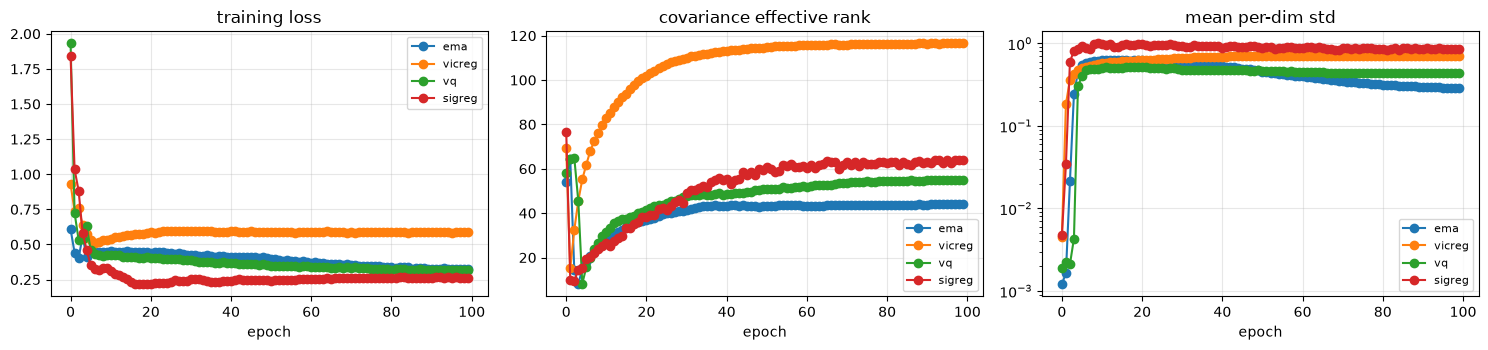

In [18]:
# --- Stage 3b: does anti-collapse buy downstream accuracy? --------------------------
# An arm that prevents collapse but destroys AUROC has not solved anything, so RQ3 is
# only answered by the (stability, accuracy) pair -- the proposal's "Pareto-best" rule.
if STAGE3 and PROBE_SPLITS:
    task_name, splits = next(iter(PROBE_SPLITS.items()))
    rows = []
    for arm, entry in STAGE3.items():
        out = run_classification_probe(entry["model"], splits, DEVICE, CFG.evaluation,
                                       batch_size=64, verbose=False)
        s = entry["res"].monitor.summary()
        rows.append({"arm": arm, "macro_auroc": out["macro_auroc"],
                     "cov_erank_ratio": s["final_cov_erank_ratio"],
                     "std_mean": s["final_std_mean"],
                     "dimensional_collapse": s["dimensional_collapse"]})
        print(f"  {arm:8s} AUROC={out['macro_auroc']:.4f}  "
              f"cov_erank_ratio={s['final_cov_erank_ratio']:.3f}")
    pareto = pd.DataFrame(rows).sort_values("macro_auroc", ascending=False)
    RESULTS["stage3_pareto"] = pareto
    print(f"\nStability vs accuracy on {task_name}:")
    display(pareto.round(4))
    best = pareto.iloc[0]
    print(f"\nPareto-best arm on this run: {best['arm']} "
          f"(AUROC {best['macro_auroc']:.4f}, cov_erank_ratio {best['cov_erank_ratio']:.3f})")

    # per-epoch trajectories, for the loss-shape diagnostic
    traj = pd.concat([entry["res"].monitor.to_frame().assign(arm=arm)
                      for arm, entry in STAGE3.items()], ignore_index=True)
    RESULTS["stage3_trajectories"] = traj
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
        for arm, entry in STAGE3.items():
            df = entry["res"].monitor.to_frame()
            axes[0].plot(df.epoch, df.loss, marker="o", label=arm)
            axes[1].plot(df.epoch, df.cov_effective_rank, marker="o", label=arm)
            axes[2].plot(df.epoch, df.std_mean, marker="o", label=arm)
        for ax, t in zip(axes, ("training loss", "covariance effective rank",
                                "mean per-dim std")):
            ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
        axes[2].set_yscale("log")
        plt.tight_layout(); plt.show()
    except Exception as exc:
        print("(plot skipped:", exc, ")")
else:
    print("Stage 3b skipped.")

save_results()

## Stage 4 — H2: hierarchical vs single-scale across horizons

The Level-2 stack pools per-window summary tokens into a minutes-long coarse sequence
and runs a second context/target/predictor triple over it — ER-JEPA's channel→temporal
factorisation, with the temporal *masking* stage replaced by temporal *forecasting*.

H2 makes a directional prediction that is easy to falsify: the hierarchical−single-scale
gap should **widen monotonically as $H$ grows**. A model that only wins at one horizon
has not demonstrated long-horizon modelling. The sweep below is the actual test, and the
monotonicity check at the end reports the verdict either way.


In [ ]:
# --- Stage 4: hierarchical stack (H2) -----------------------------------------------
# Controlled ablation: BOTH models are trained on the same wide-context loader and
# differ only in whether the Level-2 stack is enabled. Reusing Stage 1's model as the
# single-scale arm would confound the comparison, because it was trained with a
# 2-window context and its predictor's window embeddings for slots 2..11 would never
# have received a gradient.
STAGE4, sweep_df, hier_model = {}, None, None

if STAGES["stage4_hierarchical"] and any(r.episodes for r in LONG_RECORDS):
    L2W = CFG.hierarchical.l2_context_windows

    def build_stage4_cfg(name, hierarchical):
        c = copy.deepcopy(CFG)
        c.name = f"{CFG.name}_{name}"
        c.hierarchical.enabled = hierarchical
        c.forward.context_windows = L2W
        c.forward.grad_context_windows = 2      # back-prop through 2 of the 12 windows
        c.optim.batch_size = STAGE4_BATCH       # (was the typo STAGE4_BATCHl -> NameError)
        return c

    hcfg = build_stage4_cfg("hier", True)
    # same short-clip loader as Stage 1 + re-drawn wide-context pairs, training records only
    hier_long = build_forward_loader(TRAIN_LONG, hcfg,
                                     samples_per_record=200 if RUN_MODE != "smoke" else 16,
                                     batch_size=STAGE4_BATCH)
    hier_loader = combine_loaders(SHORT_LOADER, hier_long, long_weight=2.0)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print(f"wide-context loader: {len(hier_loader)} steps/epoch, batch {STAGE4_BATCH}, "
          f"context = {L2W} x {CFG.signal.window_s}s "
          f"= {L2W * CFG.signal.window_s / 60:.1f} min")

    for name, use_hier in (("hierarchical", True), ("single_scale", False)):
        cfg4 = build_stage4_cfg(name, use_hier)
        print(f"\n=== training [{name}]  level2={use_hier} ===")
        m = CardioJEPA(cfg4.signal, cfg4.model, cfg4.loss, cfg4.hierarchical, cfg4.forward)
        maybe_warm_start(m, name)
        r = cj.pretrain(m, hier_loader, cfg4, device=DEVICE, arm_name=name,
                        probe_batch=PROBE_BATCH,
                        save_path=os.path.join(cfg4.out_dir, f"stage4_{name}.pth"),
                        log_every=0 if RUN_MODE == "smoke" else 100, **CKPT_KW)
        STAGE4[name] = {"model": m, "res": r, "cfg": cfg4}
    hier_model = STAGE4["hierarchical"]["model"]

    models = {k: {"model": v["model"], "feature_mode": "world"}
              for k, v in STAGE4.items()}

    HS = ((120.0, 300.0, 600.0) if RUN_MODE == "smoke"
          else (300.0, 900.0, 1800.0, 3600.0))

    def _builder(records, signal, horizon_s, context_windows):
        return build_onset_dataset(
            records, signal, horizon_s=horizon_s, context_windows=context_windows,
            stride_s=CFG.evaluation.anticipation_stride_s,
            guard_s=CFG.evaluation.anticipation_guard_s,
            max_per_record=300 if RUN_MODE != "smoke" else 60)

    print()
    from cardio_jepa.eval.forecast import horizon_sweep_heldout
    sweep_df = horizon_sweep_heldout(models, LONG_RECORDS, CFG.signal, DEVICE,
                                     CFG.evaluation, horizons_s=HS, builder=_builder,
                                     train_ids=TRAIN_IDS, test_ids=HELD_IDS,
                                     context_windows=L2W)
    if len(sweep_df):
        RESULTS["stage4_horizon_sweep"] = sweep_df
        display(sweep_df.round(4))
        piv = sweep_df.pivot(index="horizon_s", columns="model", values="auroc")
        if {"hierarchical", "single_scale"} <= set(piv.columns):
            piv["gap"] = piv["hierarchical"] - piv["single_scale"]
            display(piv.round(4))
            gaps = piv["gap"].dropna().tolist()
            widening = len(gaps) >= 2 and all(b >= a - 1e-6 for a, b in zip(gaps, gaps[1:]))
            print(f"\nH2 -- does the hierarchical gap widen monotonically with horizon? "
                  f"{widening}")
            print("  " + ("consistent with H2" if widening
                          else "NOT consistent with H2 on this run"))
            RESULTS["stage4_h2_monotone"] = bool(widening)
else:
    print("Stage 4 skipped.")

save_results()

wide-context loader: 3549 steps/epoch, batch 16, context = 12 x 10.0s = 2.0 min

=== training [hierarchical]  level2=True ===
  step    100/354900  loss=1.9886  lr=1.68e-06  ema=0.99600
  step    200/354900  loss=2.0218  lr=2.37e-06  ema=0.99600
  step    300/354900  loss=2.1470  lr=3.06e-06  ema=0.99600
  step    400/354900  loss=2.1511  lr=3.75e-06  ema=0.99600
  step    500/354900  loss=2.2946  lr=4.44e-06  ema=0.99601
  step    600/354900  loss=0.4934  lr=5.14e-06  ema=0.99601
  step    700/354900  loss=2.4388  lr=5.83e-06  ema=0.99601
  step    800/354900  loss=1.9717  lr=6.52e-06  ema=0.99601
  step    900/354900  loss=2.1376  lr=7.21e-06  ema=0.99601
  step   1000/354900  loss=1.8210  lr=7.90e-06  ema=0.99601
  step   1100/354900  loss=1.6618  lr=8.59e-06  ema=0.99601
  step   1200/354900  loss=0.4842  lr=9.28e-06  ema=0.99601
  step   1300/354900  loss=1.3856  lr=9.97e-06  ema=0.99601
  step   1400/354900  loss=1.2495  lr=1.07e-05  ema=0.99602
  step   1500/354900  loss=1.1277 

In [ ]:
# --- Stage 4b: AF-burden regression (the other half of H2) --------------------------
if STAGE4 and any(r.episodes for r in LONG_RECORDS):
    L2W = CFG.hierarchical.l2_context_windows
    bsamples, bstats = build_burden_dataset(
        LONG_RECORDS, CFG.signal, context_windows=L2W, from_first_minutes=30.0,
        samples_per_record=8 if RUN_MODE != "smoke" else 4, seed=CFG.optim.seed)
    print(f"burden dataset: {bstats['n_samples']:.0f} samples over "
          f"{bstats['n_records']:.0f} records, mean AF burden {bstats['mean_burden']:.3f}")

    btr = restrict_to_records(bsamples, TRAIN_IDS)
    bte = restrict_to_records(bsamples, HELD_IDS)
    rows = []
    for name, entry in STAGE4.items():
        r = run_burden_probe(entry["model"], LONG_RECORDS, btr, bte, CFG.signal, DEVICE,
                             context_windows=L2W, feature_mode="world",
                             horizons_s=[1800.0], batch_size=32, verbose=False)
        rows.append({"model": name, "r2": r.get("r2"), "mae": r.get("mae"),
                     "spearman": r.get("spearman"), "note": r.get("note", "")})
        print(f"  {name:14s} R2={r.get('r2', float('nan')):.3f}  "
              f"MAE={r.get('mae', float('nan')):.3f}  "
              f"rho={r.get('spearman', float('nan')):.3f}")
    if rows:
        burden_df = pd.DataFrame(rows)
        RESULTS["stage4_burden"] = burden_df
        display(burden_df.round(4))
        if len(LONG_RECORDS) < 12:
            print("\n>>> Few records: AF burden is a per-record property, so R2 here is "
                  "estimated from a handful of distinct targets and is very noisy.")
else:
    print("Stage 4b skipped.")

save_results()

## Summary and export

Every table is written to ``results\<mode>\`` (CSV + a JSON manifest) so results
survive the session. Checkpoints and per-epoch diagnostics are under
`runs\<mode>\`.

In [ ]:
# --- export -------------------------------------------------------------------------
os.makedirs(RESULTS_DIR, exist_ok=True)
manifest = {"run_mode": RUN_MODE, "config": CFG.to_dict(),
            "datasets_found": {k: v.label for k, v in FOUND.items()},
            "n_long_records": len(LONG_RECORDS),
            "long_train_records": [LONG_RECORDS[i].name for i in TRAIN_IDS],
            "long_heldout_records": [LONG_RECORDS[i].name for i in HELD_IDS],
            "data_info": {k: v for k, v in DATA_INFO.items() if k != "long_records"},
            "tables": [], "scalars": {}}

for name, obj in RESULTS.items():
    if isinstance(obj, pd.DataFrame):
        path = os.path.join(RESULTS_DIR, f"{name}.csv")
        obj.to_csv(path, index=True)
        manifest["tables"].append(f"{name}.csv")
    else:
        manifest["scalars"][name] = obj

with open(os.path.join(RESULTS_DIR, "manifest.json"), "w") as fh:
    json.dump(manifest, fh, indent=2, default=str)

print("wrote:")
for f in sorted(os.listdir(RESULTS_DIR)):
    print("  ", os.path.join(RESULTS_DIR, f))

print("\n" + "=" * 78)
print("CARDIO-JEPA RUN SUMMARY")
print("=" * 78)
for name, obj in RESULTS.items():
    print(f"\n--- {name} ---")
    print(obj.round(4).to_string() if isinstance(obj, pd.DataFrame) else obj)

## Reading these results honestly

* **`smoke` mode proves nothing scientific.** It exists to verify that every code path
  executes. Numbers from it are not evidence about ECG.
* **Synthetic fallback is a pipeline test, not data.** If `discover()` found nothing,
  the model is being trained on Gaussian-mixture beat templates. AUROC there measures
  the generator, not cardiology.
* **The anticipation benchmark here is within-record.** It is Section 6.2 item 3
  (near-term rhythm-change onset), not item 2 (Attia-style 30-day latent-AF), which
  requires longitudinal patient-level diagnosis labels absent from the public mirrors.
  Do not compare these AUROCs to Attia et al.'s 0.87.
* **2-channel Holter data is tiled to 8 leads.** LTAFDB and MIT-BIH are not 12-lead;
  `expand_to_n_leads` replicates channels so one encoder serves both regimes. That is a
  modelling compromise, and cross-lead CroPA attention is degenerate on those records.
* **PTB-XL is read at 100 Hz** (`filename_lr`) by default and upsampled to 250 Hz. Since
  the pipeline bandpasses at 45 Hz nothing in-band is lost, but set `use_hr=True` in
  `index_ptbxl` for the 500 Hz records if you want an exact match to Kim's setup.
* **One seed.** The bootstrap CIs quantify sampling noise in the test set, not training
  variance. Multi-seed runs are needed before any claim of a significant margin.
* **Collapse is arm- and scale-dependent.** Whichever arm wins at `smoke` scale may not
  win at `kaggle` or `full` scale; the RQ3 conclusion should be drawn at the largest
  scale you can afford.

## Mapping back to the proposal

| Proposal | Where it lives |
|---|---|
| §5.2 encoders, CroPA | `models/encoder.py` (`CroPAEncoder`) |
| §5.3(a) $\mathcal{L}_{mask}$ | `models/encoder.py` (`MaskedPredictor`) + `CardioJEPA.forward` |
| §5.3(b) $\mathcal{L}_{fwd}$, horizon token | `models/forward_predictor.py` (`ForwardPredictor`) |
| §5.4 hierarchical Level 2 | `models/cardio_jepa.py` (`Level2Stack`), `SequencePredictor` |
| §5.5 four anti-collapse arms | `regularizers.py`, `ANTI_COLLAPSE_DEFAULTS` |
| §5.5 diagnostics | `diagnostics.py` (`CollapseMonitor`) |
| §5.6 patient-aware sampling | `ForwardSamplingConfig.patient_aware` (hook; needs patient IDs) |
| §6.1 pretraining corpora | `data/discovery.py`, `data/short.py`, `data/longform.py` |
| §6.2 downstream tasks | `eval/benchmarks.py` |
| §6.3 baselines | `models/baselines.py` + the `masked_only` arm |
| §6.4 bootstrap CIs, label efficiency | `eval/stats.py` |
| §7 Stage 1–4 go/no-go | Stages 1–4 above |

### Not implemented here

* **RQ4 / §5.6 cross-modal prediction** (ECG → report-text or PPG latent). None of the
  Kaggle mirrors carry paired reports or synchronous PPG, so there is nothing to predict
  against; adding it means adding a second encoder and a paired corpus.
* **External-site generalisation (§6.2 item 5)** needs a geographically distinct held-out
  cohort with consistent labels — cross-corpus label harmonisation is its own project.
* **Attia-style 30-day latent AF** — see the caveat above.
